# Backprojection

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch09/ch09-03.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import rotate

## Define parameters

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import rotate

# --- 1. PARAMETERS ---
dims = 64
half_dims = dims / 2

# Default angles requested
angles_to_use = [0, 11.25, 22.5, 33.75, 45, 56.25, 67.5, 78.75, 90]

# --- 2. GENERATE SHAPES ---
# We define all shapes exactly as in previous steps for consistency
y, x = np.ogrid[-dims//2:dims//2, -dims//2:dims//2]
diamond_intercept = 16 * np.sqrt(2)

shapes_data = {
    'Disk': (x**2 + y**2 <= 16**2).astype(float),
    'Diamond': (np.abs(x) + np.abs(y) <= diamond_intercept).astype(float),
    'Box': ((np.abs(x) <= 16) & (np.abs(y) <= 16)).astype(float),
    'Diagonal': np.clip(np.eye(dims) + np.eye(dims, k=1) + np.eye(dims, k=-1), 0, 1),
    'Cross': (((np.abs(x) <= 16) & (np.abs(y) <= 4)) | 
              ((np.abs(x) <= 4) & (np.abs(y) <= 16))).astype(float)
}

# SELECT SHAPE HERE (Using 'Disk' for this plot as requested)
current_shape_name = 'Disk'
shape_img = shapes_data[current_shape_name]

# --- 3. BACKPROJECTION ALGORITHM (No Functions) ---
# We accumulate the backprojected 'smears' into this array
backproj_sum = np.zeros((dims, dims))

# Define the coordinate range for the projection (s variable)
s_range = np.arange(-dims, dims + 1)

# Loop through each chosen angle to compute its contribution
for angle_deg in angles_to_use:
    # --- A. FORWARD PROJECTION (Calculate the 1D Profile) ---
    theta = np.radians(angle_deg)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    
    # Range of Rho (distance from center). 
    # Must cover the diagonal to avoid clipping during rotation later.
    max_rho = int(np.ceil(dims * np.sqrt(2) / 2))
    rho_values = np.arange(-max_rho, max_rho + 1)
    projection_profile = []
    
    for r in rho_values:
        # Inverse Radon transform coordinates (from Rho/Theta back to X/Y)
        # Note: We sum along the line perpendicular to Rho
        x_c = r * cos_t - s_range * sin_t + half_dims
        y_c = r * sin_t + s_range * cos_t + half_dims
        
        # Nearest neighbor interpolation
        x_idx = np.round(x_c).astype(int)
        y_idx = np.round(y_c).astype(int)
        
        # Valid indices check
        valid = (x_idx >= 0) & (x_idx < dims) & (y_idx >= 0) & (y_idx < dims)
        
        if np.any(valid):
            val_sum = np.sum(shape_img[y_idx[valid], x_idx[valid]])
        else:
            val_sum = 0.0
        projection_profile.append(val_sum)
    
    projection_profile = np.array(projection_profile)
    
    # --- B. BACKPROJECTION (Smear and Rotate) ---
    # 1. Smear: Create a 2D image where every row is the 1D profile
    # Result shape: (dims, length_of_profile)
    smeared_projection = np.tile(projection_profile, (dims, 1))
    
    # 2. Rotate: Rotate the smeared image by the angle theta
    # Note: Scipy rotates counter-clockwise. 
    # We use order=1 (linear) or 0 (nearest) for speed/style.
    rotated_projection = rotate(smeared_projection, angle_deg, reshape=True, order=1)
    
    # 3. Crop: The rotation expands the image size. We must crop to center (dims x dims).
    cy, cx = np.array(rotated_projection.shape) // 2
    start_y = cy - dims // 2
    start_x = cx - dims // 2
    
    # Safety check for cropping indices to ensure we stay within bounds
    # (Sometimes rotation outputs differ by 1 pixel depending on even/odd sizes)
    end_y = start_y + dims
    end_x = start_x + dims
    
    if start_y >= 0 and start_x >= 0 and end_y <= rotated_projection.shape[0] and end_x <= rotated_projection.shape[1]:
        cropped_projection = rotated_projection[start_y:end_y, start_x:end_x]
    else:
        # Fallback crop if calculations are slightly off boundary
        # This centers the crop robustly
        r_h, r_w = rotated_projection.shape
        c_y, c_x = r_h // 2, r_w // 2
        d_h, d_w = dims // 2, dims // 2
        cropped_projection = rotated_projection[c_y-d_h:c_y+d_h, c_x-d_w:c_x+d_w]

    # 4. Accumulate
    if cropped_projection.shape == backproj_sum.shape:
        backproj_sum += cropped_projection



## Plot

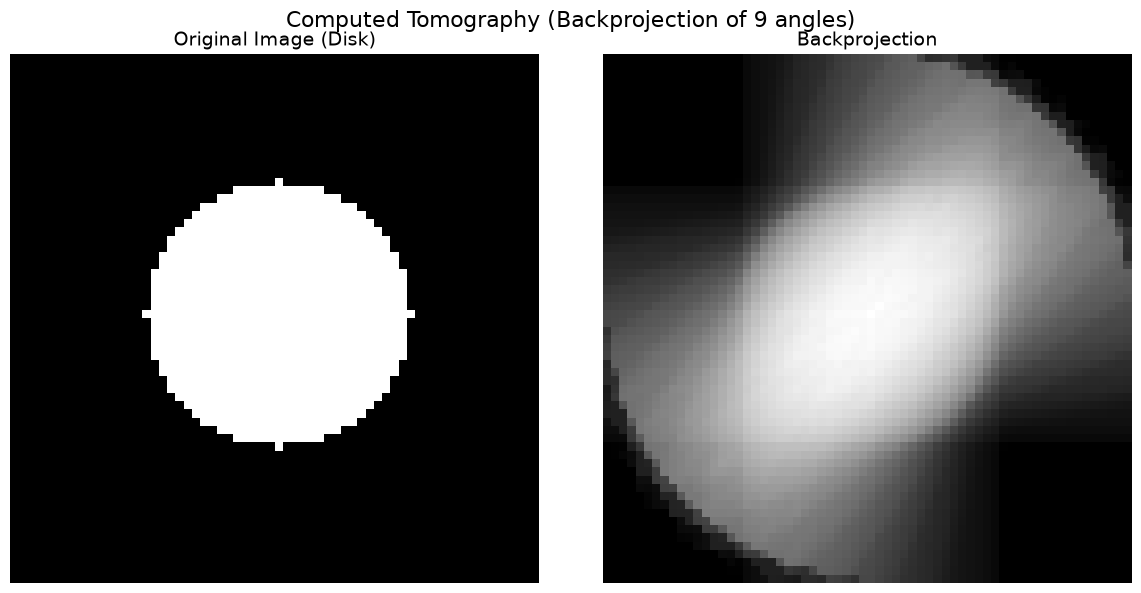

In [3]:
# --- 4. PLOTTING ---
fig1, axes1 = plt.subplots(1, 2, figsize=(12, 6))

# Subplot 1: Original Image
axes1[0].imshow(shape_img, cmap='gray', origin='lower')
axes1[0].set_title(f"Original Image ({current_shape_name})", fontsize=14)
axes1[0].axis('off')

# Subplot 2: Backprojection Sum
axes1[1].imshow(backproj_sum, cmap='gray', origin='lower')
axes1[1].set_title("Backprojection", fontsize=14)
axes1[1].axis('off')

# Dynamic Title
num_angles = len(angles_to_use)
plt.suptitle(f"Computed Tomography (Backprojection of {num_angles} angles)", fontsize=16)

plt.tight_layout()
plt.show()

## Use ipywidgets to interactively change shape and update the plot

In [4]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import rotate
from ipywidgets import interact, Dropdown, SelectMultiple, VBox, HBox, Label, Layout, interactive_output
import ipywidgets as widgets

# --- 1. PARAMETERS ---
dims2 = 64
half_dims2 = dims2 / 2

# Define the list of angles
angle_step = 11.25
all_angles = np.arange(0, 180, angle_step)

# --- 2. GENERATE SHAPES ---
y2, x2 = np.ogrid[-dims2//2:dims2//2, -dims2//2:dims2//2]
diamond_intercept2 = 16 * np.sqrt(2)
s_range2 = np.arange(-dims2, dims2 + 1)

shapes_data2 = {
    'Disk': (x2**2 + y2**2 <= 16**2).astype(float),
    'Diamond': (np.abs(x2) + np.abs(y2) <= diamond_intercept2).astype(float),
    'Box': ((np.abs(x2) <= 16) & (np.abs(y2) <= 16)).astype(float),
    'Diagonal': np.clip(np.eye(dims2) + np.eye(dims2, k=1) + np.eye(dims2, k=-1), 0, 1),
    'Cross': (((np.abs(x2) <= 16) & (np.abs(y2) <= 4)) | 
              ((np.abs(x2) <= 4) & (np.abs(y2) <= 16))).astype(float)
}

# --- 3. HELPER FUNCTION ---
def calculate_single_backprojection(img, angle_deg):
    theta = np.radians(angle_deg)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    
    # 1. Forward Projection
    max_rho = int(np.ceil(dims2 * np.sqrt(2) / 2))
    rho_values = np.arange(-max_rho, max_rho + 1)
    projection_profile = []
    
    for r in rho_values:
        x_c = r * cos_t - s_range2 * sin_t + half_dims2
        y_c = r * sin_t + s_range2 * cos_t + half_dims2
        x_idx = np.round(x_c).astype(int)
        y_idx = np.round(y_c).astype(int)
        valid = (x_idx >= 0) & (x_idx < dims2) & (y_idx >= 0) & (y_idx < dims2)
        if np.any(valid):
            val_sum = np.sum(img[y_idx[valid], x_idx[valid]])
        else:
            val_sum = 0.0
        projection_profile.append(val_sum)
    
    # 2. Smear
    smeared = np.tile(projection_profile, (dims2, 1))
    
    # 3. Rotate
    rotated = rotate(smeared, angle_deg, reshape=True, order=1)
    
    # 4. Crop
    cy, cx = np.array(rotated.shape) // 2
    start_y, start_x = cy - dims2 // 2, cx - dims2 // 2
    
    # Robust cropping
    end_y, end_x = start_y + dims2, start_x + dims2
    if start_y >= 0 and start_x >= 0 and end_y <= rotated.shape[0] and end_x <= rotated.shape[1]:
        cropped = rotated[start_y:end_y, start_x:end_x]
    else:
        r_h, r_w = rotated.shape
        c_y, c_x = r_h // 2, r_w // 2
        d_h, d_w = dims2 // 2, dims2 // 2
        cropped = rotated[c_y-d_h:c_y+d_h, c_x-d_w:c_x+d_w]
        
    return cropped

# --- 4. PRE-CALCULATION ---
print("Pre-calculating backprojections... (please wait ~10s)")
stored_backprojections = {}

for name, img in shapes_data2.items():
    shape_store = {}
    for ang in all_angles:
        shape_store[ang] = calculate_single_backprojection(img, ang)
    stored_backprojections[name] = shape_store

print("Calculation complete. Rendering layout...")

# --- 5. INTERACTIVE PLOT ---
def update_plot(shape_name, selected_angles):
    original_img = shapes_data2[shape_name]
    
    if not selected_angles:
        backproj_sum = np.zeros((dims2, dims2))
        num_angles = 0
    else:
        components = [stored_backprojections[shape_name][ang] for ang in selected_angles]
        backproj_sum = np.sum(components, axis=0)
        num_angles = len(selected_angles)
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(10, 5)) # Slightly smaller to fit side-by-side
    
    axes[0].imshow(original_img, cmap='gray', origin='lower')
    axes[0].set_title(f"Original ({shape_name})", fontsize=12)
    axes[0].axis('off')
    
    axes[1].imshow(backproj_sum, cmap='gray', origin='lower')
    axes[1].set_title(f"Reconstruction", fontsize=12)
    axes[1].axis('off')
    
    plt.suptitle(f"Summing {num_angles} Angles", fontsize=14)
    plt.tight_layout()
    plt.show()

# --- 6. WIDGET LAYOUT ---

# 1. Shape Dropdown
shape_dropdown = Dropdown(
    options=list(shapes_data2.keys()),
    value='Disk',
    description='Shape:',
    style={'description_width': 'initial'}
)

# 2. Angle Selector
default_selection = tuple(all_angles[::2])
angle_selector = SelectMultiple(
    options=list(all_angles),
    value=default_selection,
    rows=16,
    layout=Layout(width='150px', height='350px')
)

# 3. Create Output Widget
out = interactive_output(update_plot, {'shape_name': shape_dropdown, 'selected_angles': angle_selector})

# 4. Assemble Layout
# Top: Shape Dropdown
# Bottom: HBox of [Plot Output, Angle Selector VBox]
angle_ui = VBox([Label("Select Angles (Ctrl+Click):"), angle_selector])
bottom_row = HBox([out, angle_ui])

final_ui = VBox([shape_dropdown, bottom_row])

display(final_ui)

Pre-calculating backprojections... (please wait ~10s)
Calculation complete. Rendering layout...


### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch09/ch09-03_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch09/ch09-03.html) (direct link: [ch09-03_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch09/ch09-03_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.